# Exploratory Data Analysis (EDA)

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / 'main.py').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import config

%matplotlib inline

In [2]:
data = pd.read_csv(config.paths.train_data)
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

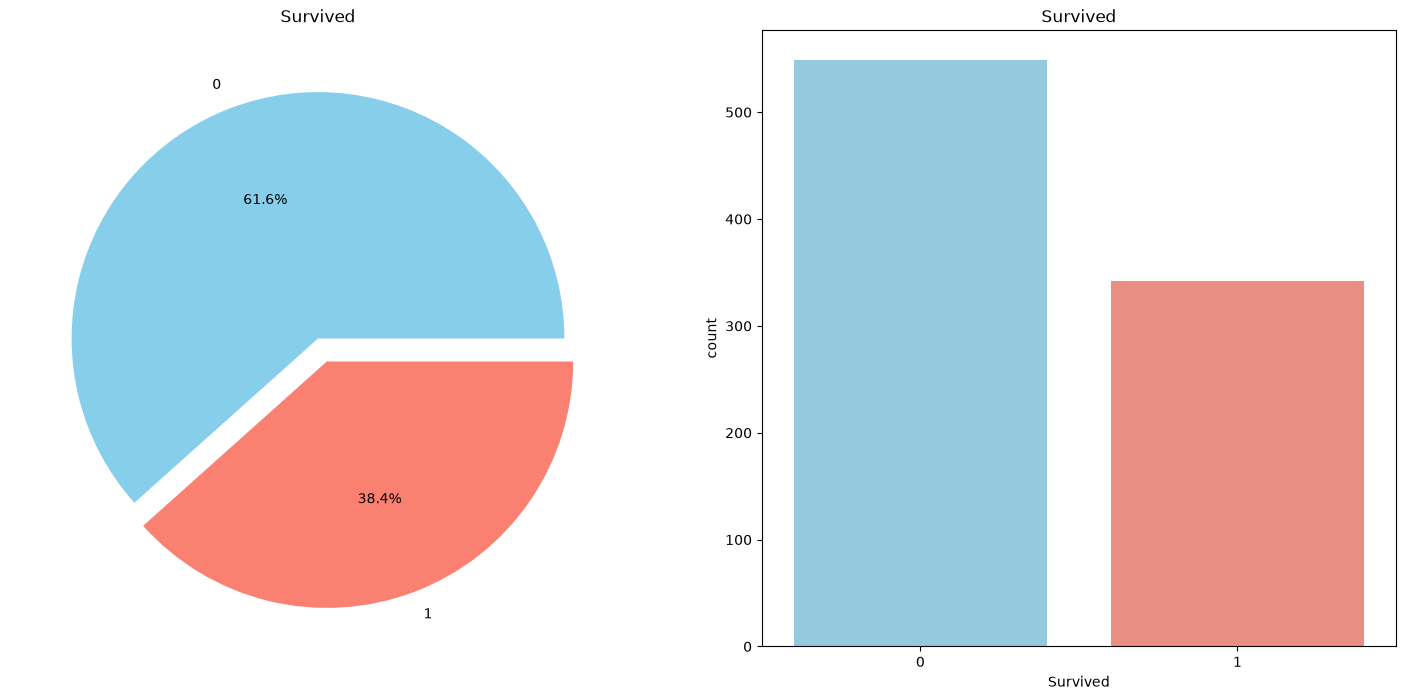

In [4]:
f, ax = plt.subplots(1,2,figsize=(18,8))

data['Survived'].value_counts().plot.pie(
    explode=[0,0.1],
    autopct='%1.1f%%',
    ax=ax[0],
    colors=['skyblue', 'salmon']
)

ax[0].set_title('Survived')
ax[0].set_ylabel('')

sns.countplot(
    x='Survived',
    data=data,
    hue='Survived',
    palette=['skyblue', 'salmon'],
    legend=False,
    ax=ax[1]
)
ax[1].set_title('Survived')

plt.show()


## Исследование влияния пола и класса обслуживания на выживаемость

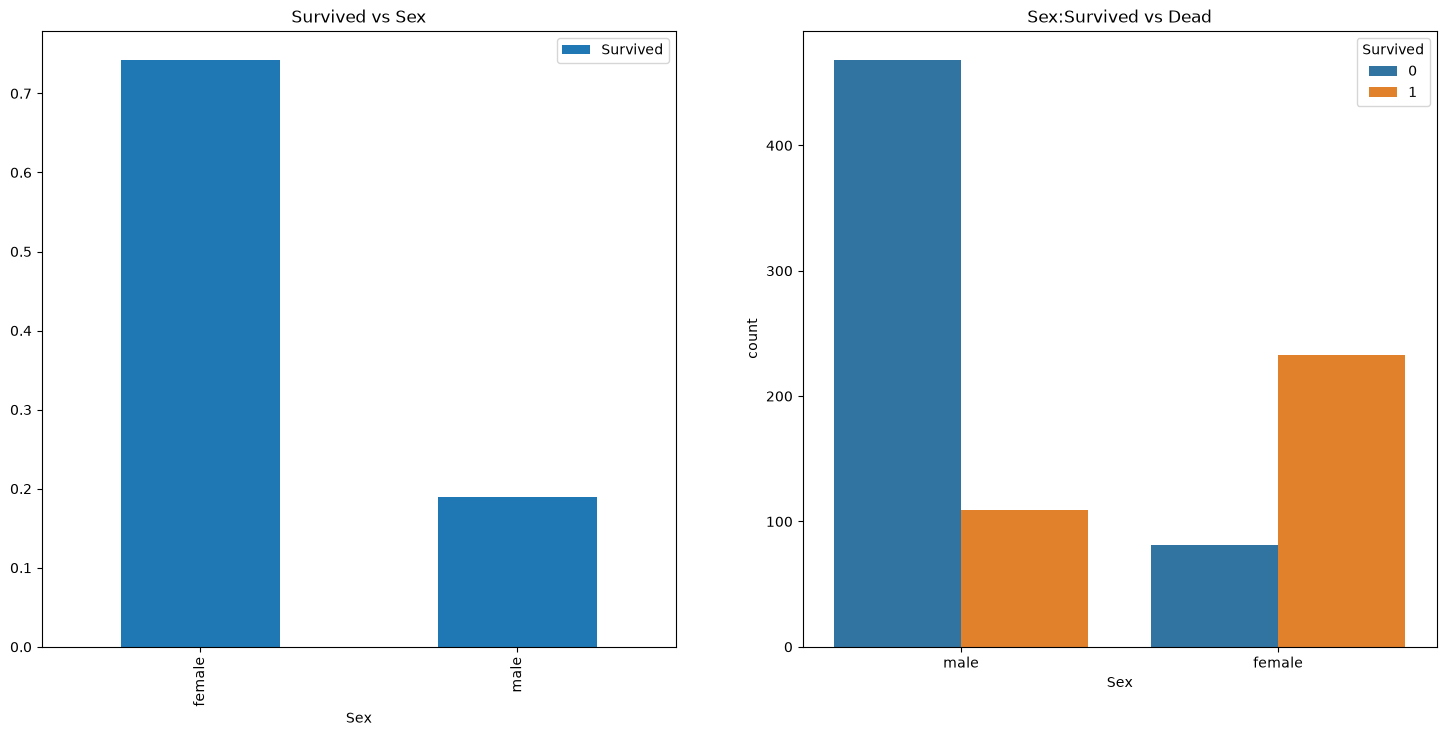

In [5]:
f,ax=plt.subplots(1,2,figsize=(18,8))
data[['Sex','Survived']].groupby(['Sex']).mean().plot.bar(ax=ax[0])
ax[0].set_title('Survived vs Sex')
sns.countplot(x='Sex',hue='Survived',data=data,ax=ax[1])
ax[1].set_title('Sex:Survived vs Dead')
plt.show()

Женщин выжило почти в 2 раза больше, чем мужчин, при том, что всего мужчин на корабле было больше, чем женщин

In [6]:
pd.crosstab(data.Pclass, data.Survived, margins=True).style.background_gradient(cmap='summer_r')

Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


Похоже, что пассажиры первого класса имели более высокий приоритет при спасении, чем пассажиры остальных классов

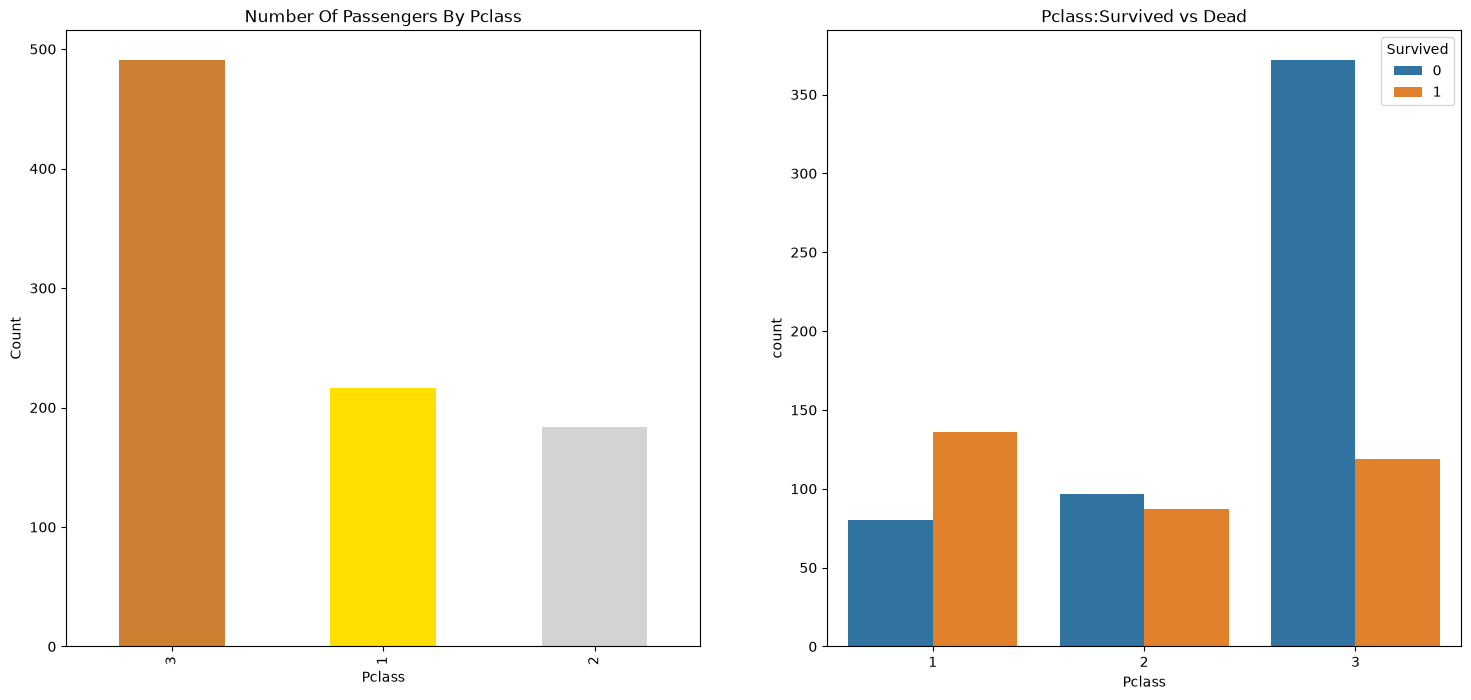

In [7]:
f,ax=plt.subplots(1,2,figsize=(18,8))
data['Pclass'].value_counts().plot.bar(color=['#CD7F32','#FFDF00','#D3D3D3'],ax=ax[0])
ax[0].set_title('Number Of Passengers By Pclass')
ax[0].set_ylabel('Count')
sns.countplot(x='Pclass',hue='Survived',data=data,ax=ax[1])
ax[1].set_title('Pclass:Survived vs Dead')
plt.show()

In [8]:
pd.crosstab([data.Sex, data.Survived], data.Pclass, margins=True).style.background_gradient(cmap='summer_r')

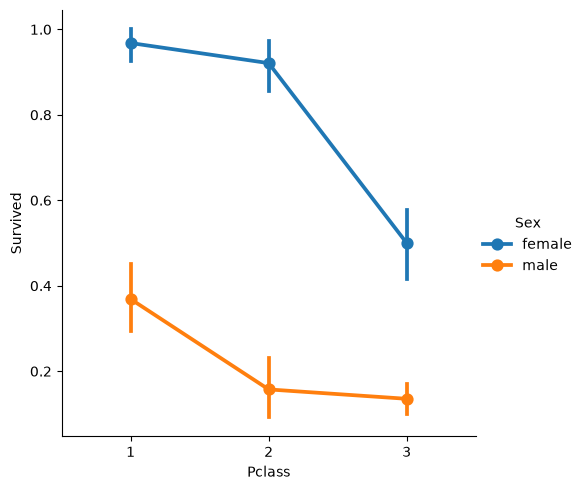

In [9]:
sns.catplot(
    data=data,
    x='Pclass',
    y='Survived',
    hue='Sex',
    kind='point'
)

plt.show()

Даже несмотря на класс женщины выживают значительно чаще, чем мужчины. При этом видно, чем доля выживших снижается и у мужчин, и у женщин, при ухудшении класса обслуживания

## Влияние возраста на выживаемость

In [10]:
print('Oldest age: ', data['Age'].max())
print('Youngest age: ', data['Age'].min())
print('Average age: ', round(data['Age'].mean(), 2))

Oldest age:  80.0
Youngest age:  0.42
Average age:  29.7


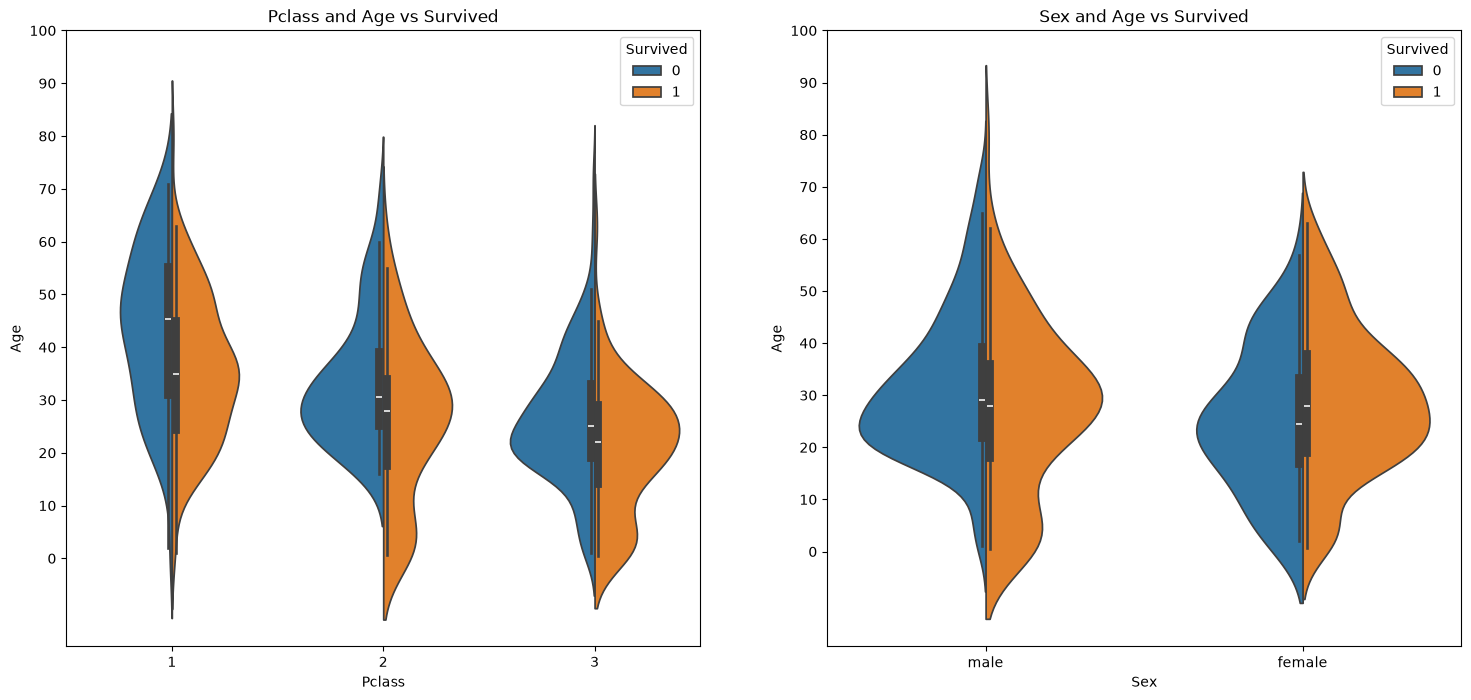

In [11]:
f, ax = plt.subplots(1,2,figsize=(18,8))
sns.violinplot(x='Pclass',y='Age',hue='Survived',data=data,split=True,ax=ax[0])
ax[0].set_title('Pclass and Age vs Survived')
ax[0].set_yticks(range(0,110,10))

sns.violinplot(x='Sex', y='Age', hue='Survived', data=data, split=True, ax=ax[1])
ax[1].set_title('Sex and Age vs Survived')
ax[1].set_yticks(range(0,110,10))

plt.show()

1. Дети (до 10 лет) выживают часто независимо от класса
2. Чем выше возраст мужчины, тем меньше его шанс выжить
3. Шанс выжить у человека 20-50 лет из класса 1 выше, чем шанс умереть

## Влияние порта посадки на выживаемость

In [12]:
pd.crosstab([data.Embarked, data.Pclass], [data.Sex, data.Survived], margins=True).style.background_gradient(cmap='summer_r')

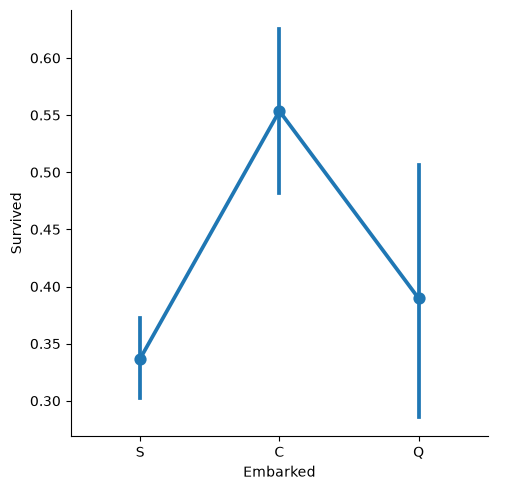

In [13]:
sns.catplot(x='Embarked', y='Survived', data=data, kind='point')
plt.show()

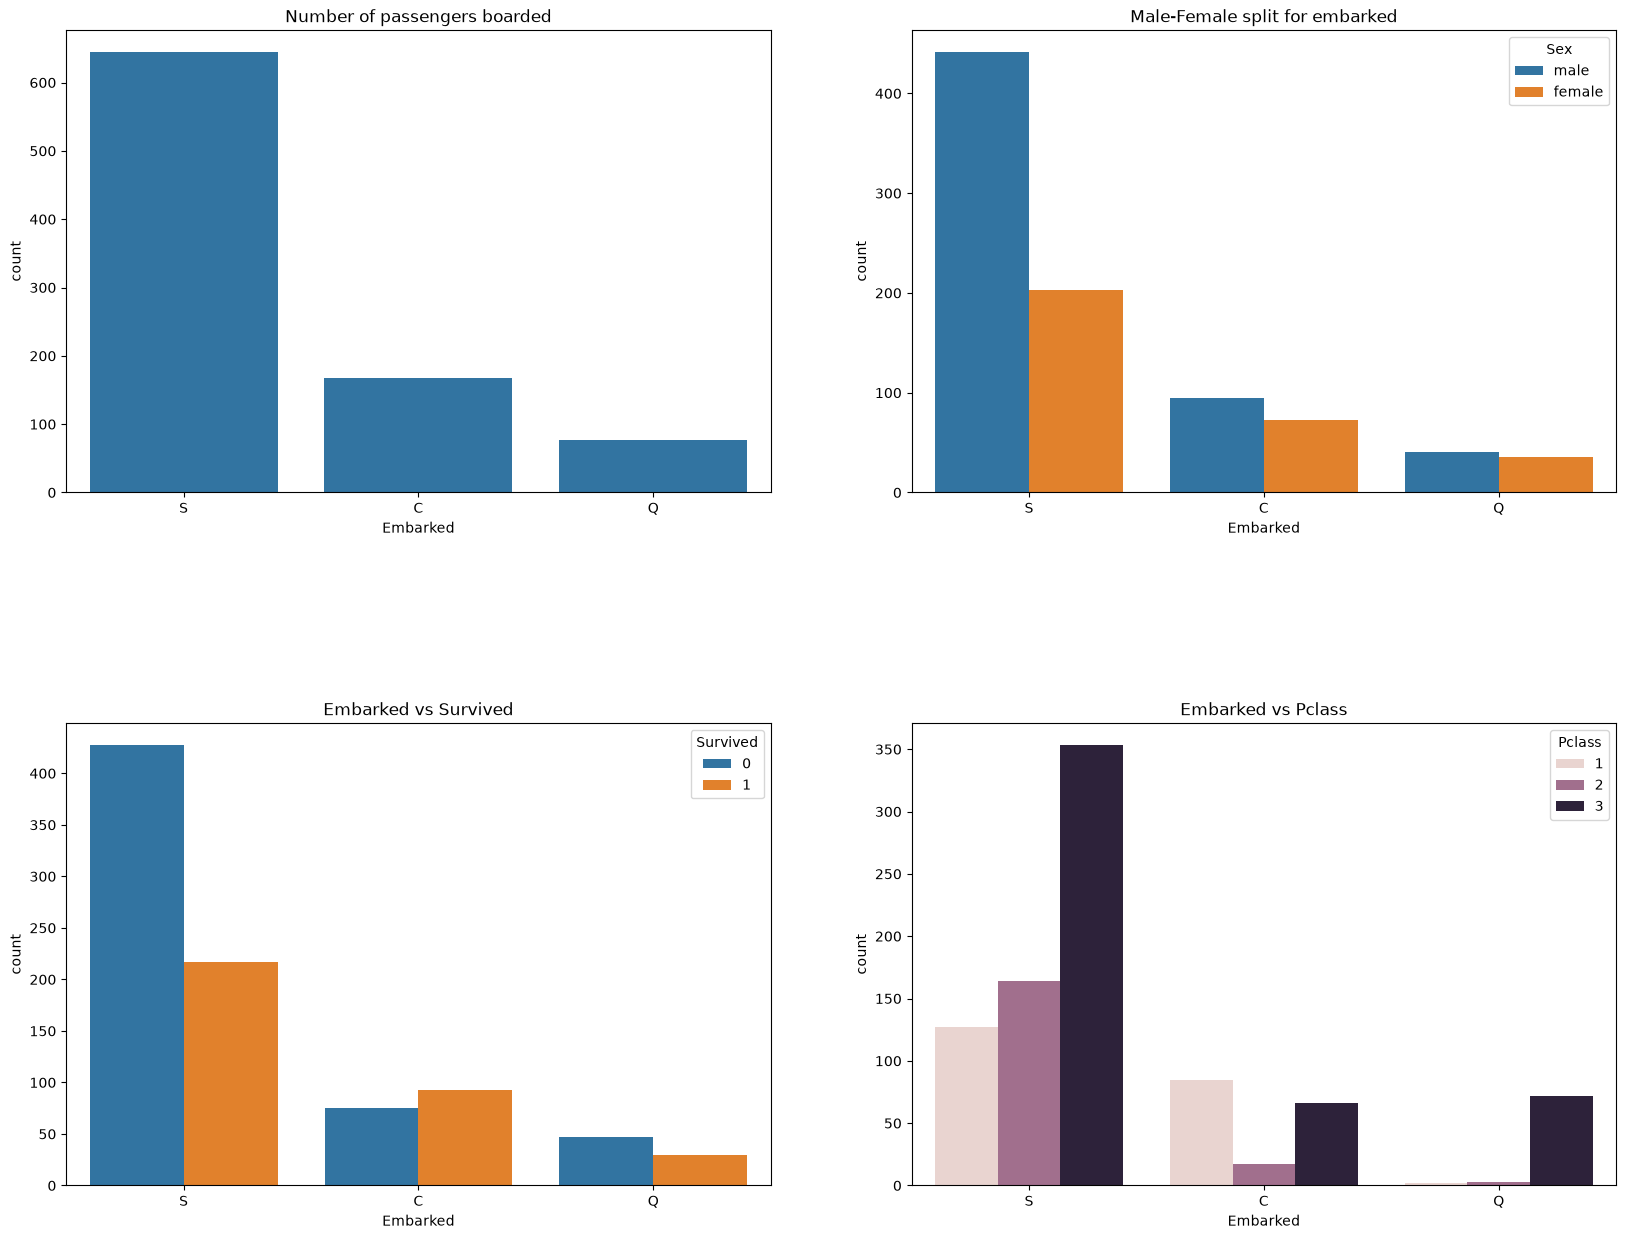

In [14]:
f,ax = plt.subplots(2,2,figsize=(20,15))
sns.countplot(x='Embarked', data=data, ax=ax[0,0])
ax[0,0].set_title('Number of passengers boarded')

sns.countplot(x='Embarked', hue='Sex', data=data, ax=ax[0,1])
ax[0,1].set_title('Male-Female split for embarked')

sns.countplot(x='Embarked', hue='Survived', data=data, ax=ax[1,0])
ax[1,0].set_title('Embarked vs Survived')

sns.countplot(x='Embarked', hue='Pclass', data=data, ax=ax[1,1])
ax[1,1].set_title('Embarked vs Pclass')

plt.subplots_adjust(wspace=0.2, hspace=0.5)
plt.show()

1. Большинство пассажиров сели в порту S. Большинство из них были из класса 3. Это может быть причиной низкой выживаемости пассажиров с этого порта
2. Пассажиры, севшие в порту C, выживали чаще. Это может быть связано с большой долей класса 1 среди пассажиров, севших на борт в этом порту

## Влияние количества членов семьи пассажира на выживаемость

In [15]:
pd.crosstab([data.SibSp], data.Survived).style.background_gradient(cmap='summer_r')

Survived,0,1
SibSp,,
0,398,210
1,97,112
2,15,13
3,12,4
4,15,3
5,5,0
8,7,0


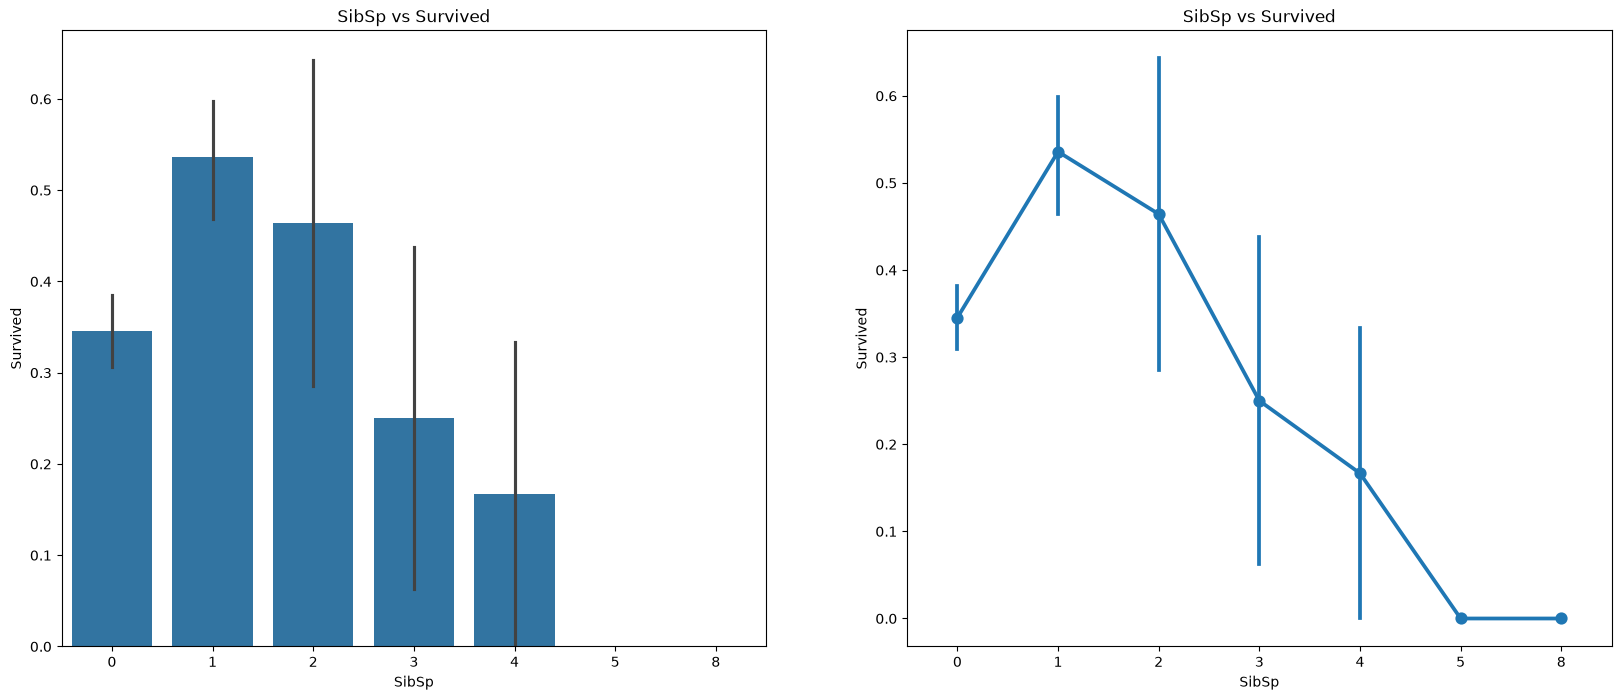

In [16]:
f, ax = plt.subplots(1,2,figsize=(20,8))

sns.barplot(x='SibSp', y = 'Survived', data=data, ax=ax[0])
ax[0].set_title('SibSp vs Survived')

sns.pointplot(x='SibSp', y='Survived', data=data, ax=ax[1])
ax[1].set_title('SibSp vs Survived')

plt.show()

In [17]:
pd.crosstab(data.SibSp, data.Pclass).style.background_gradient(cmap='summer_r')

Pclass,1,2,3
SibSp,,,
0,137,120,351
1,71,55,83
2,5,8,15
3,3,1,12
4,0,0,18
5,0,0,5
8,0,0,7


1. Если пассажир один, то его выживаемость составляет примерно 35%
2. При возрастании количества родственников выживаемость снижается. Это может быть связано с тем, что при наличии семьи человек будет пытаться спасти сначала близких людей, а потом себя

## Выводы EDA

- Пол (Sex): выживаемость женщин выше выживаемости мужчин
- Класс обслуживания (Pclass): пассажиры первого класса имели большую выживаемость, чем пассажиры более низких классов
- Возраст (Age): дети до 10 лет имели высокий шанс выжить. Наиболее часто умирали пассажиры возраста 15-35 лет
- Порт посадки (Embarkment): пассажиры с порта C имели более высокие шансы выжить
- Количество членов семьи на борту (Parch, SibSp): наличие 1-2 родственников на борту увеличивало вероятность выжить по сравнению с путешествием в одиночку. Дальнейшее увеличение членов семьи на борту наоборот уменьшает выживаемость пассажира